# 02 — Graph analysis: benign vs attack traffic

Each 5-minute window becomes a directed graph: hosts are nodes and flows are edges carrying the flow features. This notebook builds one real window graph, compares benign and attack sources on graph measures, and shows the subgraph of flows flagged by E-GraphSAGE.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import yaml, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
cfg = yaml.safe_load(Path('configs/experiment.yaml').read_text())
metrics = json.loads(Path('results/metrics.json').read_text())
import networkx as nx
from src.data import load_cic, add_windows
from src.build_graph import build_graph_windows, STRUCT_NAMES
flows = add_windows(load_cic(cfg['data']['path']), cfg['data']['window_seconds'])
scan = flows[(flows['_attack_type'] == 'PortScan')]
w = scan['_window'].value_counts().index[0]
window = flows[flows['_window'] == w].reset_index(drop=True)
g = build_graph_windows(window, np.zeros((len(window), 1), dtype=np.float32))[0]
print(f"Window starting {window['_datetime'].min():%A %H:%M}: {len(window):,} flows, {g.struct_x.shape[0]} hosts, "
      f"{int(g.y.sum()):,} PortScan flows")

/content/graph-network-intrusion-gnn/src/data.py:99: UserWarning: Dropping 288602 rows with missing labels.
  warnings.warn(f"Dropping {(~keep).sum()} rows with missing labels.")


Window starting Friday 14:50: 97,730 flows, 380 hosts, 93,096 PortScan flows


## Structural node features in that window

These six features are computed from the graph only. A scanner stands out immediately: it contacts many distinct ports.

In [2]:
hosts = sorted(set(g.src_hosts) | set(g.dst_hosts))
feats = pd.DataFrame(np.expm1(g.struct_x.numpy()).round().astype(int), index=hosts, columns=[n.replace('log_', '') for n in STRUCT_NAMES])
display(feats.sort_values('distinct_dst_ports', ascending=False).head(8))

,out_degree,in_degree,distinct_destinations,distinct_sources,distinct_dst_ports,distinct_src_ports_seen
172.16.0.1,93097,488,2,1,998,396
192.168.10.50,560,93169,15,11,288,12964
104.97.74.19,31,32,1,1,29,30
216.58.219.193,26,31,4,4,26,29
217.118.87.98,19,27,1,1,19,25
172.217.10.98,16,16,3,2,16,15
172.217.9.238,16,29,6,5,16,24
104.20.115.18,15,54,1,1,15,35


## Benign vs attack sources (protocol B test windows)

,destinations_mean,destinations_median,destinations_max,ports_mean,ports_median,ports_max,flows_mean,flows_median,flows_max
Attack,1.0,1.0,1.0,54.5,1.0,1000.0,536.6,5.0,9027.0
Benign,3.0,1.0,201.0,2.4,1.0,784.0,11.7,1.0,1307.0


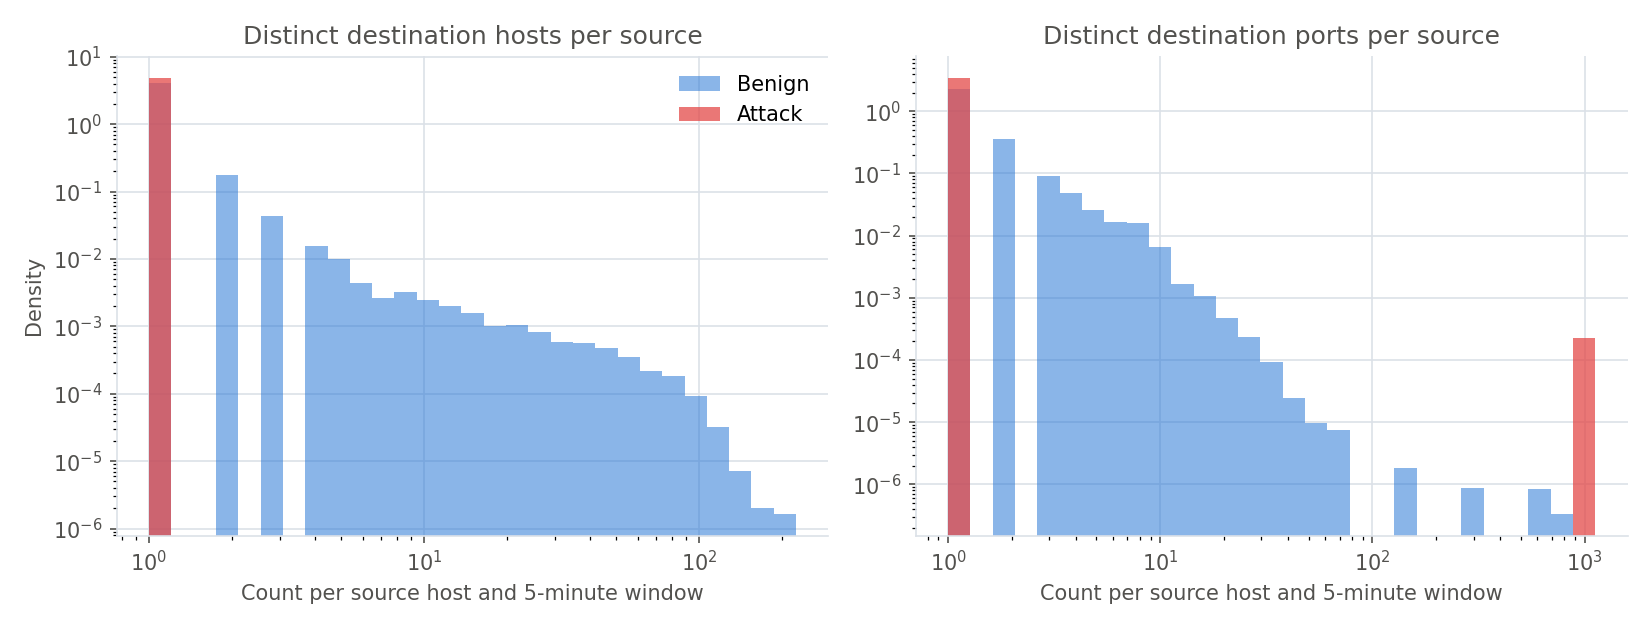

In [3]:
ga = json.loads(Path('results/graph_analysis.json').read_text())
display(pd.DataFrame(ga['per_source_summary']).T.round(1))
display(Image(filename='results/graph_comparison.png'))

## Attack subgraph flagged by the model

Flows scored above the validation-tuned threshold in one test window. Red edges are truly malicious flows, blue edges are false alarms. The red node is the most connected host.

{
 "port_scan": {
  "window": 4998133,
  "source": "172.16.0.1",
  "target": "192.168.10.50",
  "distinct_ports": 999,
  "flagged_flows": 9027
 }
}


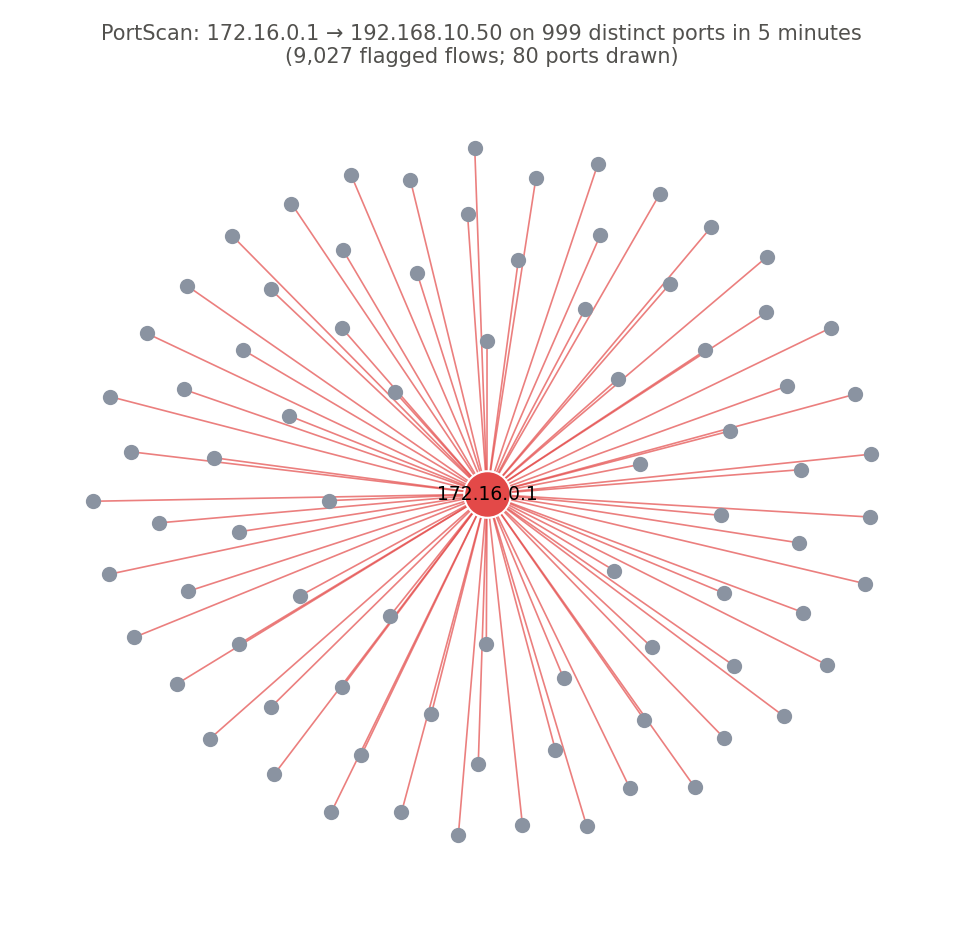

In [4]:
print(json.dumps(ga['attack_subgraph'], indent=1))
display(Image(filename='results/attack_subgraph.png'))

## From this project to lateral movement

Lateral movement is an attacker moving from one internal machine to the next. The same building blocks apply: hosts as nodes, timestamped host-to-host events (authentications, remote sessions, process launches) as edges, and short time windows. Two changes are needed. First, provenance graphs from system logs have typed nodes (process, file, socket, user) and typed edges (read, write, fork, connect), so a heterogeneous or temporal GNN (for example R-GCN or TGN) fits better than the homogeneous GraphSAGE used here. Second, an attack is a path across several nodes and windows, so detections must be joined: link anomalous edges that share a host and follow each other in time, and score the resulting chains. Evaluating that needs path-level labels (for example the LANL or DARPA OpTC datasets) and splits by time and by host.